In [2]:
import base64
import io
import json
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import norm
from PIL import Image
from zipfile import ZipFile, ZIP_DEFLATED


In [3]:
ROOT = Path.cwd().resolve()
if ROOT.name == 'src':
    ROOT = ROOT.parent.parent
IN = ROOT / 'c_analyze/input/upstream'
OUT = ROOT / 'c_analyze/output'
cfg = json.loads((IN / 'config.json').read_text())
SEED = cfg['seed']
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
colors = sns.color_palette('colorblind', 3)
styles = ['-', '--', ':']
markers = ['o', 's', '^']
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180, 'axes.spines.top': False,'axes.spines.right': False, 'font.size': 10})


In [4]:
baseline = dict(np.load(IN / 'baseline.npz'))
experiments = {block: dict(np.load(IN / f'wind_L{block}.npz')) for block in cfg['wind_blocks']}
audit = pd.read_csv(IN / 'mass_balance.csv')
weather = dict(np.load(IN / 'weather_demo.npz'))
weather_audit = pd.read_csv(IN / 'weather_demo_audit.csv')


In [5]:
y = np.arange(cfg['ny']) - cfg['source_y']
kernel = np.zeros((cfg['nx'], cfg['ny']))
kernel[0, cfg['source_y']] = 1
d = cfg['diffusivity']
for x in range(1, cfg['nx']):
    kernel[x] = (1 - 2*d) * kernel[x-1]
    kernel[x, 1:] += d * kernel[x-1, :-1]
    kernel[x, :-1] += d * kernel[x-1, 1:]
baseline_mean = baseline['mean_grid'].mean(axis=0) / cfg['packets_per_step']
profile_rows = []
for x in range(1, cfg['nx']):
    sigma = np.sqrt(2*d*x)
    gaussian = norm.cdf((y+.5)/sigma) - norm.cdf((y-.5)/sigma)
    p = baseline_mean[x]
    mu = np.sum(y*p)
    profile_rows.append({'x': x, 'mean_y': mu, 'empirical_variance': np.sum((y-mu)**2*p),
        'predicted_variance': 2*d*x, 'total_variation_exact': .5*np.abs(p-kernel[x]).sum(),
        'total_variation_gaussian': .5*np.abs(p-gaussian).sum()})
baseline_metrics = pd.DataFrame(profile_rows)
baseline_metrics.to_csv(OUT / 'baseline_metrics.csv', index=False)
baseline_metrics.loc[baseline_metrics['x'].isin(cfg['profile_distances'])].round(4)


,x,mean_y,empirical_variance,predicted_variance,total_variation_exact,total_variation_gaussian
11,12,0.0051,5.2913,5.28,0.0013,0.0026
29,30,0.0061,13.2316,13.20,0.0016,0.0018
47,48,0.0062,21.1793,21.12,0.0015,0.0016


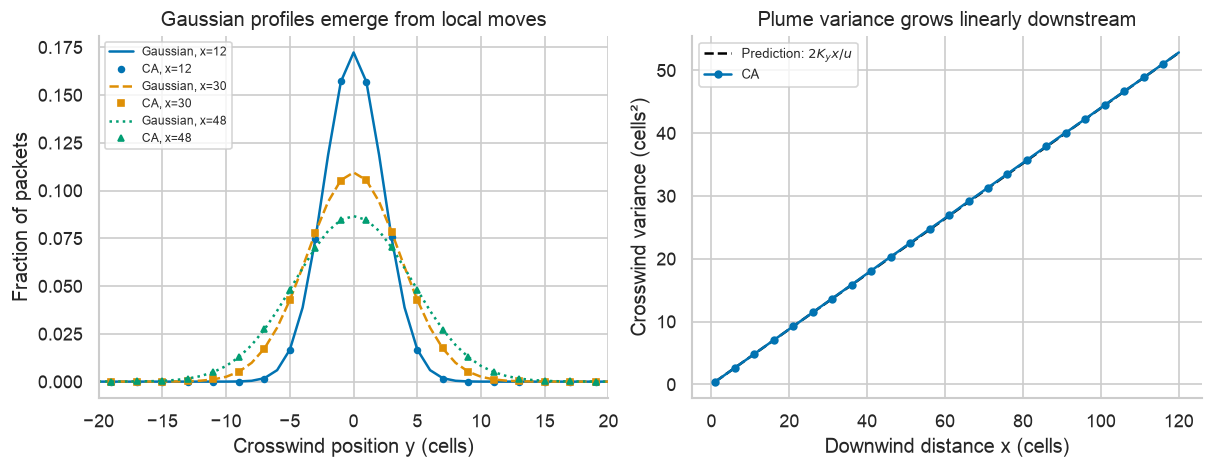

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
for j, x in enumerate(cfg['profile_distances']):
    sigma = np.sqrt(2*d*x)
    gaussian = norm.cdf((y+.5)/sigma) - norm.cdf((y-.5)/sigma)
    axes[0].plot(y, gaussian, color=colors[j], ls=styles[j], label=f'Gaussian, x={x}')
    axes[0].plot(y, baseline_mean[x], color=colors[j], ls='none', marker=markers[j],
                 ms=3.5, markevery=2, label=f'CA, x={x}')
axes[0].set(xlim=(-20, 20), xlabel='Crosswind position y (cells)', ylabel='Fraction of packets',
            title='Gaussian profiles emerge from local moves')
axes[0].legend(fontsize=7, loc='upper left')
axes[1].plot(baseline_metrics['x'], baseline_metrics['predicted_variance'], color='black',
             ls='--', label=r'Prediction: $2K_yx/u$')
axes[1].plot(baseline_metrics['x'], baseline_metrics['empirical_variance'], color=colors[0],
             marker='o', markevery=5, ms=4, label='CA')
axes[1].set(xlabel='Downwind distance x (cells)', ylabel='Crosswind variance (cells²)',
            title='Plume variance grows linearly downstream')
axes[1].legend(fontsize=8)
fig.savefig(OUT / '01_gaussian_benchmark.png')
plt.show()


In [7]:
def exposure_episodes(values, threshold):
    above = values > threshold
    changes = np.diff(np.r_[False, above, False].astype(np.int8))
    starts = np.flatnonzero(changes == 1)
    stops = np.flatnonzero(changes == -1)
    complete = (starts > 0) & (stops < len(values))
    return stops[complete] - starts[complete], int((~complete).sum())

trial_rows = []
for block, exp in experiments.items():
    trace = exp['trace'][:, cfg['burn_in']:]
    for trial in range(cfg['n_trials']):
        for j, offset in enumerate(cfg['receptor_offsets']):
            values = trace[trial, :, j]
            durations, censored = exposure_episodes(values, cfg['exposure_threshold'])
            trial_rows.append({'block': block, 'trial': trial, 'initial': exp['initial'][trial],
                'receptor_y': offset, 'mean_concentration': values.mean(),
                'exposure_fraction': (values > cfg['exposure_threshold']).mean(),
                'complete_episodes': len(durations), 'complete_duration_sum': durations.sum(),
                'censored_episodes': censored,
                'mean_complete_duration': durations.mean() if len(durations) else np.nan})
trials = pd.DataFrame(trial_rows)
trials.to_csv(OUT / 'trial_metrics.csv', index=False)


In [8]:
def summarize_trials(group, rng, draws):
    strata = [part for _, part in group.groupby('initial', sort=False)]
    samples = []
    for part in strata:
        a = part[['mean_concentration', 'exposure_fraction', 'complete_episodes', 'complete_duration_sum']].to_numpy()
        index = rng.integers(0, len(a), size=(draws, len(a)))
        samples.append(a[index].sum(axis=1))
    totals = np.sum(samples, axis=0)
    boot_mean = totals[:, 0] / len(group)
    boot_exposure = totals[:, 1] / len(group)
    boot_duration = np.divide(totals[:, 3], totals[:, 2], out=np.full(draws, np.nan), where=totals[:, 2] > 0)
    episodes = group['complete_episodes'].sum()
    duration = group['complete_duration_sum'].sum() / episodes if episodes else np.nan
    return {'mean_concentration': group['mean_concentration'].mean(),
        'mean_lo': np.quantile(boot_mean, .025), 'mean_hi': np.quantile(boot_mean, .975),
        'exposure_fraction': group['exposure_fraction'].mean(),
        'exposure_lo': np.quantile(boot_exposure, .025), 'exposure_hi': np.quantile(boot_exposure, .975),
        'mean_complete_duration': duration, 'duration_lo': np.nanquantile(boot_duration, .025),
        'duration_hi': np.nanquantile(boot_duration, .975), 'complete_episodes': episodes,
        'censored_episodes': group['censored_episodes'].sum(), 'trials': len(group)}

summary = pd.DataFrame([dict(block=block, receptor_y=offset,
    **summarize_trials(group, rng, cfg['bootstrap_draws']))
    for (block, offset), group in trials.groupby(['block', 'receptor_y'], sort=True)])
summary.to_csv(OUT / 'exposure_summary.csv', index=False)
summary.round(3)


,block,receptor_y,mean_concentration,mean_lo,mean_hi,exposure_fraction,exposure_lo,exposure_hi,mean_complete_duration,duration_lo,duration_hi,complete_episodes,censored_episodes,trials
0,1,-12,0.290,0.282,0.299,0.000,0.000,0.001,1.412,1.000,1.857,17,0,64
1,1,0,6.628,6.592,6.661,0.967,0.962,0.972,41.772,37.181,47.098,1133,124,64
2,1,12,0.289,0.280,0.298,0.000,0.000,0.001,1.294,1.091,1.571,17,0,64
3,8,-12,1.090,1.050,1.132,0.099,0.092,0.107,12.002,10.869,13.239,514,18,64
4,8,0,4.481,4.391,4.572,0.572,0.557,0.587,6.662,6.374,6.971,5498,58,64
5,8,12,1.090,1.046,1.135,0.098,0.089,0.106,11.549,10.489,12.774,543,11,64
6,32,-12,2.088,2.039,2.136,0.279,0.269,0.289,33.249,30.695,36.134,526,26,64
7,32,0,2.304,2.202,2.405,0.289,0.275,0.302,5.758,5.608,5.921,3242,41,64
8,32,12,2.092,2.040,2.144,0.280,0.270,0.291,33.392,31.089,35.972,510,33,64


In [9]:
wind_rows = []
for block, exp in experiments.items():
    wind = exp['wind'][:, cfg['burn_in']:].astype(float)
    for trial in range(cfg['n_trials']):
        w = wind[trial]
        wind_rows.append({'block': block, 'trial': trial, 'positive_fraction': (w==1).mean(),
            'lag1_correlation': np.corrcoef(w[:-1], w[1:])[0, 1],
            'lag16_correlation': np.corrcoef(w[:-16], w[16:])[0, 1],
            'observed_mean_run': len(w)/(1+np.count_nonzero(np.diff(w)))})
wind_metrics = pd.DataFrame(wind_rows)
wind_metrics.to_csv(OUT / 'wind_metrics.csv', index=False)
wind_metrics.groupby('block').mean(numeric_only=True).drop(columns='trial').round(3)


,positive_fraction,lag1_correlation,lag16_correlation,observed_mean_run
block,,,,
1,0.5,0.003,0.000,2.006
8,0.5,0.874,-0.024,15.808
32,0.5,0.969,0.498,61.863


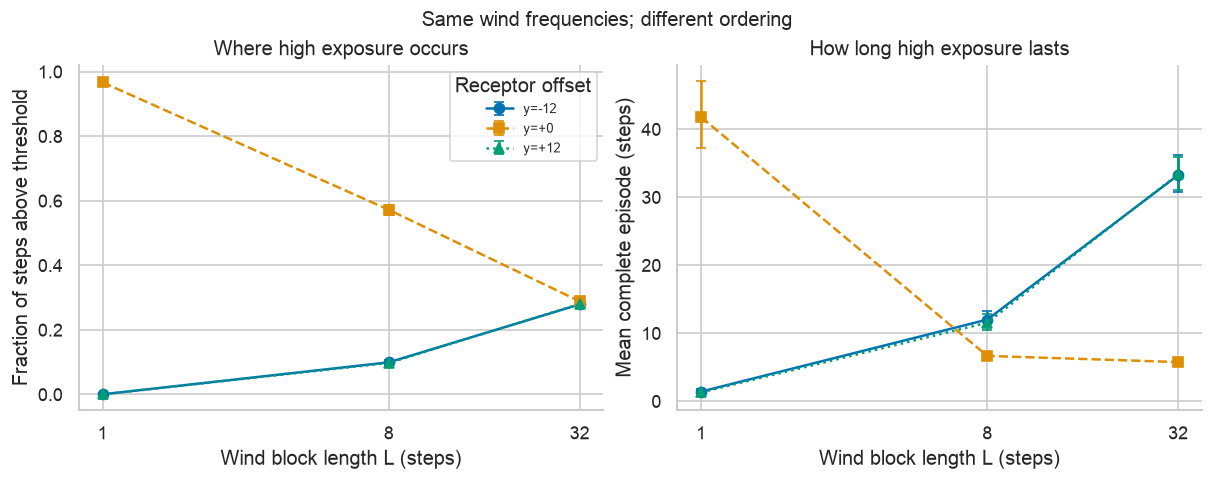

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), constrained_layout=True)
for j, offset in enumerate(cfg['receptor_offsets']):
    part = summary.loc[summary['receptor_y'].eq(offset)]
    for ax, value, lo, hi in [
        (axes[0], 'exposure_fraction', 'exposure_lo', 'exposure_hi'),
        (axes[1], 'mean_complete_duration', 'duration_lo', 'duration_hi')
    ]:
        ax.errorbar(part['block'], part[value],
            yerr=np.vstack([part[value]-part[lo], part[hi]-part[value]]),
            color=colors[j], marker=markers[j], ls=styles[j], capsize=3, label=f'y={offset:+d}')
        ax.set(xscale='log', xticks=cfg['wind_blocks'])
        ax.set_xticklabels(cfg['wind_blocks'])
        ax.set_xlabel('Wind block length L (steps)')
axes[0].set(ylabel='Fraction of steps above threshold', title='Where high exposure occurs')
axes[1].set(ylabel='Mean complete episode (steps)', title='How long high exposure lasts')
axes[0].legend(title='Receptor offset', fontsize=8)
fig.suptitle('Same wind frequencies; different ordering', fontsize=12)
fig.savefig(OUT / '02_exposure_results.png')
plt.show()


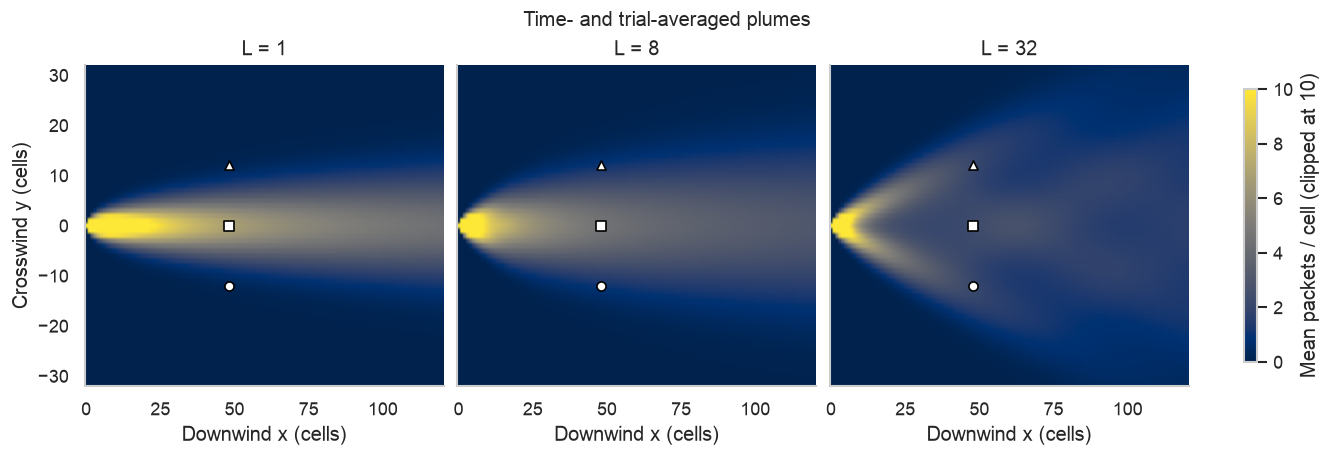

In [11]:
means = [exp['mean_grid'].mean(axis=0) for exp in experiments.values()]
vmax = 10  # common display limit; high source-adjacent values clipped
fig, axes = plt.subplots(1, 3, figsize=(11, 3.7), constrained_layout=True, sharey=True)
for ax, (block, exp), mean in zip(axes, experiments.items(), means):
    image = ax.imshow(mean.T, origin='lower', extent=(-.5, cfg['nx']-.5, y[0]-.5, y[-1]+.5),
        aspect='auto', cmap='cividis', vmin=0, vmax=vmax)
    for j, offset in enumerate(cfg['receptor_offsets']):
        ax.scatter(cfg['receptor_x'], offset, marker=markers[j], s=30, c='white', edgecolors='black')
    ax.set(xlabel='Downwind x (cells)', ylim=(-32, 32), title=f'L = {block}')
    ax.grid(False)
axes[0].set_ylabel('Crosswind y (cells)')
fig.colorbar(image, ax=axes, label='Mean packets / cell (clipped at 10)', shrink=.85)
fig.suptitle('Time- and trial-averaged plumes', fontsize=12)
fig.savefig(OUT / '03_mean_plumes.png')
plt.show()


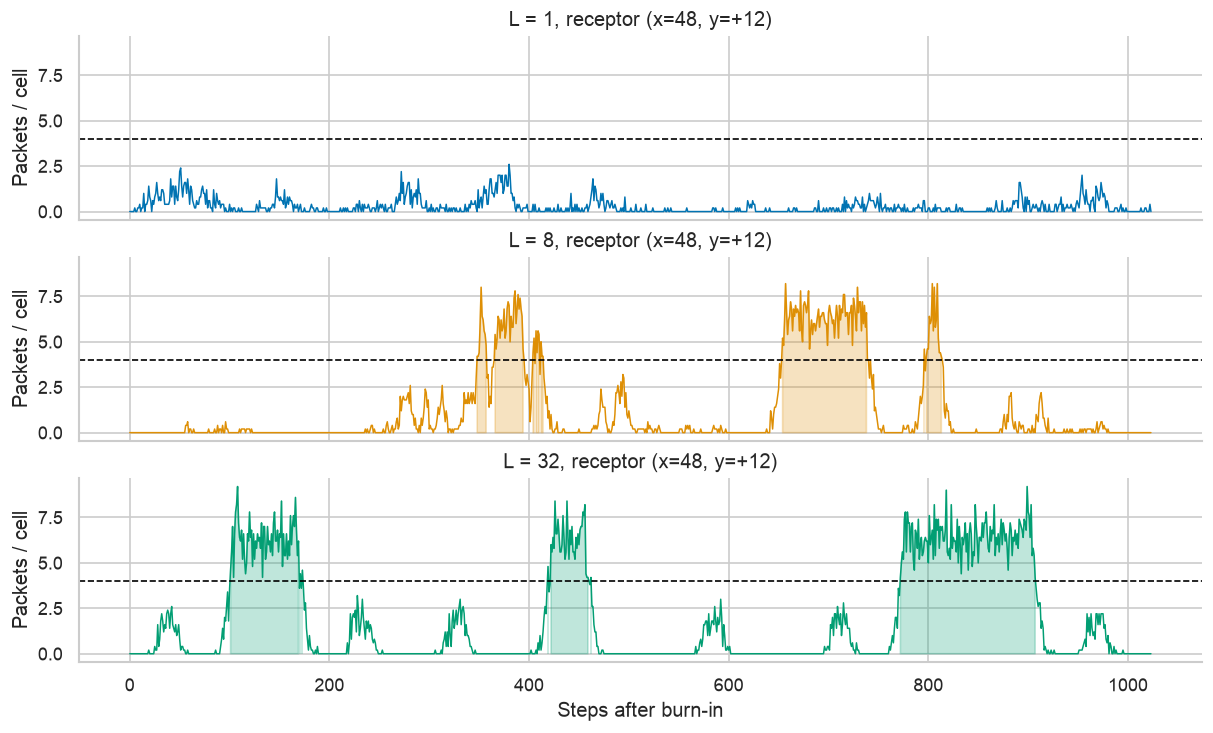

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(10, 6), constrained_layout=True, sharex=True, sharey=True)
time_axis = np.arange(cfg['n_steps'])
j = cfg['receptor_offsets'].index(12)
for i, (ax, (block, exp)) in enumerate(zip(axes, experiments.items())):
    values = exp['trace'][0, cfg['burn_in']:, j]
    sns.lineplot(x=time_axis, y=values, ax=ax, color=colors[i], lw=.9)
    ax.axhline(cfg['exposure_threshold'], color='black', ls='--', lw=1)
    ax.fill_between(time_axis, 0, values, where=values>cfg['exposure_threshold'], color=colors[i], alpha=.25)
    ax.set(ylabel='Packets / cell', title=f'L = {block}, receptor (x=48, y=+12)')
axes[-1].set_xlabel('Steps after burn-in')
fig.savefig(OUT / '04_exposure_histories.png')
plt.show()


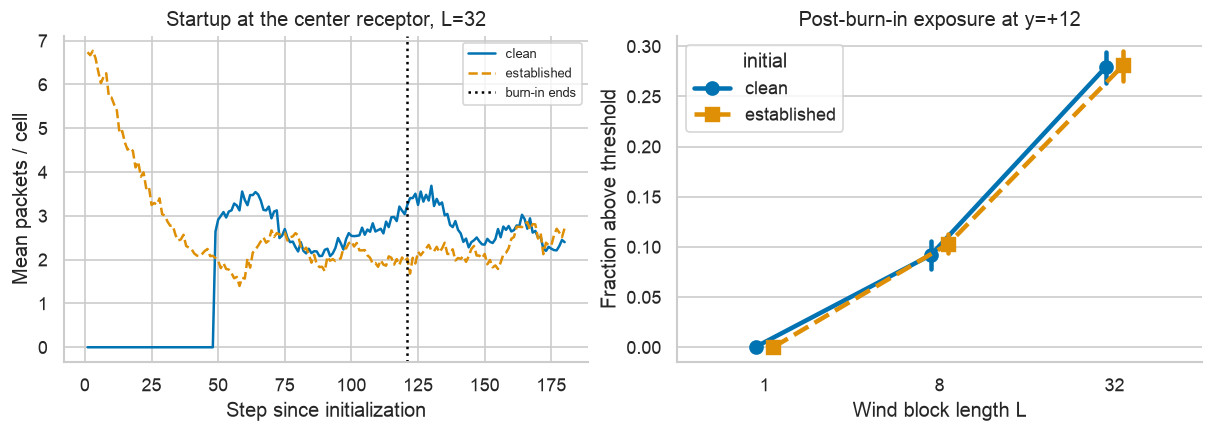

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
exp = experiments[32]
j = cfg['receptor_offsets'].index(0)
for k, initial in enumerate(['clean', 'established']):
    keep = exp['initial'] == initial
    mean_trace = exp['trace'][keep, :180, j].mean(axis=0)
    axes[0].plot(np.arange(180)+1, mean_trace, color=colors[k], ls=styles[k], label=initial)
axes[0].axvline(cfg['burn_in'], color='black', ls=':', label='burn-in ends')
axes[0].set(xlabel='Step since initialization', ylabel='Mean packets / cell', title='Startup at the center receptor, L=32')
axes[0].legend(fontsize=8)
sns.pointplot(data=trials.loc[trials['receptor_y'].eq(12)], x='block', y='exposure_fraction',
    hue='initial', palette=colors[:2], markers=['o', 's'], linestyles=['-', '--'],
    errorbar=('ci', 95), n_boot=1000, seed=SEED, dodge=.1, ax=axes[1])
axes[1].set(xlabel='Wind block length L', ylabel='Fraction above threshold', title='Post-burn-in exposure at y=+12')
fig.savefig(OUT / '05_initial_conditions.png')
plt.show()


In [14]:
sensitivity_rows = []
for block, exp in experiments.items():
    trace = exp['trace'][:, cfg['burn_in']:]
    for threshold in [2., 4., 6.]:
        for j, offset in enumerate(cfg['receptor_offsets']):
            sensitivity_rows.append({'block': block, 'receptor_y': offset, 'threshold': threshold,
                'exposure_fraction': (trace[:, :, j] > threshold).mean()})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUT / 'threshold_sensitivity.csv', index=False)
sensitivity.loc[sensitivity['receptor_y'].eq(12)].pivot(index='block', columns='threshold', values='exposure_fraction').round(3)


threshold,2.0,4.0,6.0
block,,,
1,0.009,0.000,0.000
8,0.175,0.098,0.047
32,0.333,0.280,0.166


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4), constrained_layout=True, sharey=True)
artists = []
for ax, block in zip(axes, [1, 32]):
    image = ax.imshow(experiments[block]['frames'][0].T, origin='lower',
        extent=(-.5, cfg['nx']-.5, y[0]-.5, y[-1]+.5), aspect='auto', cmap='cividis', vmin=0, vmax=15)
    ax.scatter([cfg['receptor_x']]*3, cfg['receptor_offsets'], c='white', edgecolors='black', s=20)
    ax.set(xlabel='Downwind x', ylim=(-30, 30))
    ax.grid(False)
    artists.append(image)
axes[0].set_ylabel('Crosswind y')
fig.colorbar(artists[0], ax=axes, label='Packets / cell (clipped at 15)', shrink=.8)
gif_frames = []
n_frames = min(len(experiments[block]['frames']) for block in [1, 32])
for frame in range(n_frames):
    step = frame*cfg['frame_interval']
    for ax, image, block in zip(axes, artists, [1, 32]):
        image.set_data(experiments[block]['frames'][frame].T)
        sign = experiments[block]['wind'][0, step]
        label = 'Rapid changes' if block == 1 else 'Persistent direction'
        ax.set_title(f'{label}\nL={block}, step={step+1}, sign={sign:+d}')
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=90)
    buffer.seek(0)
    gif_frames.append(Image.open(buffer).convert('RGB'))
plt.close(fig)
gif_path = OUT / 'plume_comparison.gif'
gif_frames[0].save(gif_path, save_all=True, append_images=gif_frames[1:], duration=100, loop=0)
encoded = base64.b64encode(gif_path.read_bytes()).decode()
display({'text/html': f'<img alt="Rapid versus persistent wind plume" src="data:image/gif;base64,{encoded}">'}, raw=True)


In [ ]:
side = summary.loc[summary['receptor_y'].eq(12)].set_index('block')
base = baseline_metrics.set_index('x').loc[cfg['receptor_x']]
result_notes = pd.DataFrame([
    ['baseline crosswind var at x=48', f"CA {base['empirical_variance']:.3f}; pred. {base['predicted_variance']:.3f}"],
    ['off-center exposure frac, L=1 -> L=32', f"{side.loc[1, 'exposure_fraction']:.3%} -> {side.loc[32, 'exposure_fraction']:.3%}"],
    ['off-center complete episode duration, L=1 -> L=32', f"{side.loc[1, 'mean_complete_duration']:.2f} -> {side.loc[32, 'mean_complete_duration']:.2f} steps"],
    ['off-center complete episodes at L=1', f"{int(side.loc[1, 'complete_episodes'])}"],
    ['mass balance', f"max abs packet err = {audit['max_mass_balance_error'].max()}"],
], columns=['quantity', 'result'])
result_notes.to_csv(OUT / 'findings.csv', index=False)
result_notes


,quantity,result
0,baseline crosswind var at x=48,CA 21.179; pred. 21.120
1,"off-center exposure frac, L=1 -> L=32",0.034% -> 28.024%
2,"off-center complete episode duration, L=1 -> L=32",1.29 -> 33.39 steps
3,off-center complete episodes at L=1,17
4,mass balance,max abs packet err = 0


In [ ]:
# weather comparison — mean flow is distinct from persistence and random spreading
weather_methods = pd.DataFrame([
    ['rapid changes', 'Original CA', '1 eastward; +/-0.30 sideways', 'L=1: wind sign changes frequently'],
    ['persistent direction', 'Original CA', '1 eastward; +/-0.30 sideways', 'L=32: wind sign tends to persist'],
    ['gentle steady wind', 'Supplemental CA', f"{cfg['weather_demo']['gentle_drift']:.2f} eastward; 0 sideways", 'Weak constant eastward drift'],
    ['calm', 'Supplemental CA', '0 in both directions', 'Random diffusion continues; pollutant accumulates near source'],
    ['comparison scope', 'One realization per panel', 'All emit 80 packets/step', 'Same crosswind diffusivity; gentle/calm also diffuse longitudinally'],
    ['initial conditions', 'All initially clean', 'Common time, space, and color scale', 'Original exposure statistics apply only to original experiments']
], columns=['condition', 'model', 'mean_drift_cells_per_step', 'interpretation'])
weather_methods.to_csv(OUT / 'weather_demo_methods.csv', index=False)
weather_methods


,condition,model,mean_drift_cells_per_step,interpretation
0,rapid changes,Original CA,1 eastward; +/-0.30 sideways,L=1: wind sign changes frequently
1,persistent direction,Original CA,1 eastward; +/-0.30 sideways,L=32: wind sign tends to persist
2,gentle steady wind,Supplemental CA,0.15 eastward; 0 sideways,Weak constant eastward drift
3,calm,Supplemental CA,0 in both directions,Random diffusion continues; pollutant accumula...
4,comparison scope,One realization per panel,All emit 80 packets/step,Same crosswind diffusivity; gentle/calm also d...
5,initial conditions,All initially clean,"Common time, space, and color scale",Original exposure statistics apply only to ori...


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(9.6, 5.8), dpi=90,
    layout='compressed', sharex=True, sharey=True)
cmap = plt.colormaps['cividis'].with_extremes(bad=plt.colormaps['cividis'](0))
norm_color = LogNorm(vmin=1, vmax=320, clip=True)
labels = ['Rapid direction changes (L=1)', 'Persistent direction (L=32)',
          'Gentle steady wind', 'Calm: zero mean wind']
extents = [(-.5, cfg['nx']-.5, y[0]-.5, y[-1]+.5)]*2
extents += [(weather['x'][0]-.5, weather['x'][-1]+.5,
             weather['y'][0]-.5, weather['y'][-1]+.5)]*2
first = [experiments[1]['frames'][0], experiments[32]['frames'][0],
         weather['frames'][0, 0], weather['frames'][0, 1]]
weather_images = []
arrows = []
for ax, label, extent, values in zip(axes.flat, labels, extents, first):
    ax.set_facecolor(cmap(0))
    image = ax.imshow(np.ma.masked_less(values.T, 1), origin='lower', extent=extent,
        aspect='equal', cmap=cmap, norm=norm_color)
    arrow = ax.quiver(-25, 0, 0, 0, angles='xy', scale_units='xy', scale=1,
        color='white', width=.008, headwidth=4, headlength=5)
    ax.scatter(0, 0, marker='x', s=35, linewidths=1.2, c='white')
    ax.set(title=label, xlim=(-40, 120), ylim=(-40, 40))
    ax.grid(False)
    weather_images.append(image)
    arrows.append(arrow)
for ax in axes[-1]:
    ax.set_xlabel('Eastward position x (cells)')
for ax in axes[:, 0]:
    ax.set_ylabel('Crosswind position y (cells)')
colorbar = fig.colorbar(weather_images[0], ax=axes, shrink=.8, pad=.02,
    ticks=[1, 4, 16, 64, 256], label='Packets / cell (log scale)')
colorbar.ax.set_yticklabels(['1', '4', '16', '64', '256'])
title = fig.suptitle('Initially clean air; all sources emit 80 packets/step', fontsize=12)
fig.supxlabel('White arrows: relative mean drift; white crosses: emission source', fontsize=9)
fig.canvas.draw()
fig.set_layout_engine(None)
weather_gif_frames = []
n_frames = min(len(weather['steps']), len(experiments[1]['frames']), len(experiments[32]['frames']))
for frame, step in enumerate(weather['steps'][:n_frames]):    
    t = int(step)-1
    values = [experiments[1]['frames'][frame], experiments[32]['frames'][frame],
              weather['frames'][frame, 0], weather['frames'][frame, 1]]
    directions = [(1., cfg['wind_bias']*experiments[1]['wind'][0, t]),
                  (1., cfg['wind_bias']*experiments[32]['wind'][0, t]),
                  (cfg['weather_demo']['gentle_drift'], 0.), (0., 0.)]
    for image, arrow, data, (ux, uy) in zip(weather_images, arrows, values, directions):
        image.set_data(np.ma.masked_less(data.T, 1))
        arrow.set_UVC(14*ux, 14*uy)
        arrow.set_visible(ux != 0 or uy != 0)
    title.set_text(f'Step {step} | Initially clean air | 80 packets emitted per step')
    fig.canvas.draw()
    weather_gif_frames.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[:, :, :3].copy()))
    if frame == n_frames-1:
        fig.savefig(OUT / '06_weather_conditions.png', dpi=180)
plt.close(fig)
weather_gif_path = OUT / 'weather_comparison.gif'
weather_gif_frames[0].save(weather_gif_path, save_all=True, append_images=weather_gif_frames[1:],
    duration=100, loop=0)
encoded_weather = base64.b64encode(weather_gif_path.read_bytes()).decode()
display({'text/html': f'<img alt="Rapid changes, persistent direction, gentle wind, and calm air" src="data:image/gif;base64,{encoded_weather}">'}, raw=True)


NameError: name 'plt' is not defined

In [ ]:
calm = weather['frames'][-1, 1].astype(float)
calm_mass = calm.sum()
mean_x = (calm*weather['x'][:, None]).sum()/calm_mass
mean_y = (calm*weather['y'][None, :]).sum()/calm_mass
calm_check = pd.DataFrame([
    ['mean x', mean_x, 0.], ['mean y', mean_y, 0.],
    ['variance x', (calm*(weather['x'][:, None]-mean_x)**2).sum()/calm_mass,
        cfg['diffusivity']*(weather['steps'][-1]-1)],
    ['variance y', (calm*(weather['y'][None, :]-mean_y)**2).sum()/calm_mass,
        cfg['diffusivity']*(weather['steps'][-1]-1)]
], columns=['quantity', 'CA', 'unbounded_grid_expectation'])
calm_check.to_csv(OUT / 'calm_diffusion_check.csv', index=False)
display(weather_audit)
calm_check


,condition,steps,mean_eastward_drift,emitted,remaining,exited,max_mass_balance_error
0,gentle,1433,0.15,114640,76821,37819,0
1,calm,1433,0.00,114640,114579,61,0


,quantity,CA,unbounded_grid_expectation
0,mean x,0.026610,0.00
1,mean y,-0.036394,0.00
2,variance x,313.871494,315.04
3,variance y,313.491165,315.04


In [ ]:
weather_gif_path = OUT / 'weather_comparison.gif'
weather_zip_path = OUT / 'weather_overleaf.zip'

with Image.open(weather_gif_path) as gif, ZipFile(weather_zip_path, 'w', ZIP_DEFLATED) as archive:
    n_frames = gif.n_frames
    for i in range(n_frames):
        gif.seek(i)
        buffer = io.BytesIO()
        gif.convert('RGB').save(buffer, format='PNG')
        archive.writestr(f'weather_frames/frame-{i:04d}.png', buffer.getvalue())

    latex = (r"\animategraphics[autoplay,loop,controls,width=\linewidth]"
             f"{{10}}{{weather_frames/frame-}}{{0000}}{{{n_frames-1:04d}}}")
    archive.writestr('weather_animation.tex', latex)

pd.DataFrame({'file': [str(weather_zip_path)], 'frames': [n_frames]})

,file,frames
0,/Users/slmagid/Desktop/MOCS/Assignment2/c_anal...,144


In [ ]:
plume_gif_path = OUT / 'plume_comparison.gif'
plume_zip_path = OUT / 'plume_overleaf.zip'

with Image.open(plume_gif_path) as gif, ZipFile(plume_zip_path, 'w', ZIP_DEFLATED) as archive:
    n_frames = gif.n_frames
    for i in range(n_frames):
        gif.seek(i)
        buffer = io.BytesIO()
        gif.convert('RGB').save(buffer, format='PNG')
        archive.writestr(f'plume_frames/frame-{i:04d}.png', buffer.getvalue()) 

    latex = (r"\animategraphics[autoplay,loop,controls,width=\linewidth]"
             f"{{10}}{{plume_frames/frame-}}{{0000}}{{{n_frames-1:04d}}}")
    archive.writestr('plume_animation.tex', latex)

pd.DataFrame({'file': [str(plume_zip_path)], 'frames': [n_frames]})

,file,frames
0,/Users/slmagid/Desktop/MOCS/Assignment2/c_anal...,144
